# Text Preprocessing in Natural Language Processing
> **Author: Mason Swanson**
> About 9 minutes to read (2,279 words)

Natural language processing hit a boom in popularity in recent decades. With that popularity comes increased demand for those who understand how to program natural language processing applications. Beyond that, it's actually kinda fun to do some light text analysis on your home computer. 

But how do you get your text ready to be analyzed by a computer? You need to perform preprocessing.

This article will cover three parts of preprocessing in NLP: Tokenization, Stemming, and Lemmatization.

## What is Tokenization?
When reading natural language into a computer program, it immediately becomes necessary to identify the boundaries between words. The simple text—"the boy kicked the ball"—can be split into "the" "boy" "kicked" "the" "ball" by choosing to use a space as a delimiter.

In [1]:
alep = "the boy kicked the ball".split(" ")
alep

['the', 'boy', 'kicked', 'the', 'ball']

This is effective for cases where all of your text is separated by spaces, with no other punctuation, and where capitalization matters. We can see the frequency of each word using some form of counter:

In [2]:
from collections import Counter
Counter(alep)

Counter({'the': 2, 'boy': 1, 'kicked': 1, 'ball': 1})

Unfortunately, this simple approach does not work in more complicated examples:

In [3]:
bet = """Yes or no isn't null; yes it is; no, I don't know
Yes or no? Isn't it a silly question? Ask it anyway, 'cause""".split(" ")
bet

['Yes',
 'or',
 'no',
 "isn't",
 'null;',
 'yes',
 'it',
 'is;',
 'no,',
 'I',
 "don't",
 'know\nYes',
 'or',
 'no?',
 "Isn't",
 'it',
 'a',
 'silly',
 'question?',
 'Ask',
 'it',
 'anyway,',
 "'cause"]

In [4]:
Counter(bet)

Counter({'it': 3,
         'or': 2,
         'Yes': 1,
         'no': 1,
         "isn't": 1,
         'null;': 1,
         'yes': 1,
         'is;': 1,
         'no,': 1,
         'I': 1,
         "don't": 1,
         'know\nYes': 1,
         'no?': 1,
         "Isn't": 1,
         'a': 1,
         'silly': 1,
         'question?': 1,
         'Ask': 1,
         'anyway,': 1,
         "'cause": 1})

The counter is differentiating between `Yes` and `yes`, and it's not separating `know` and `yes` in `know\nYes`. It's also creating different counts for `no`, `no,`, and `no?`.

We can force the text to be all uppercase or lowercase, and we could add more separators, but this quickly becomes complicated. 

### Complications With Splitting Text
Typically, an apostrophe character is used in computer text as either a single quote or an apostrophe. Take this example sentence:
> He said 'don't don that t-shirt' to Don---who was doing dishes.
1. If we normalized capitalization, we would be unable to differentiate between don (to put on) and Don (nickname for Donovan).
    - This can sometimes be ignored, but it can be a problem in languages like Turkish where the capital form of i is İ, and the lowercase form of I is ı. Kir means "dirt" but Kır means "countryside".
2. If we added punctuation to the list of separators, we wouldn't have to worry about the single quotes merging into the words `don't` or `t-shirt` or the hypens merging `Don---who`.
    - But we'd end up splitting `don't` into `don` & `t`; and `t-shirt` into `t` & `shirt`.

### Introducing: NLTK Tokenizers
Thankfully, computational linguists have created tools for assisting with these problems. NLTK contains various tokenizers that follow different philosophies. 

As an example, here's how `ToktokTokenizer` performs on the last example sentence:

In [5]:
# Natural Language processing tools
import nltk
from nltk.tokenize.toktok import ToktokTokenizer

giml = "He said 'don't don that t-shirt' to Don---who was doing dishes."

lower_giml = giml.lower()

tokenizer = ToktokTokenizer()
tokenized = tokenizer.tokenize(lower_giml)

tokenized

['he',
 'said',
 "'",
 'don',
 "'",
 't',
 'don',
 'that',
 't-shirt',
 "'",
 'to',
 'don',
 '---',
 'who',
 'was',
 'doing',
 'dishes',
 '.']

Now with `TreebankWordTokenizer`:


In [6]:
from nltk.tokenize.treebank import TreebankWordTokenizer

tokenizer = TreebankWordTokenizer()
tokenized = tokenizer.tokenize(lower_giml)

tokenized

['he',
 'said',
 "'do",
 "n't",
 'don',
 'that',
 't-shirt',
 "'",
 'to',
 'don',
 '--',
 '-who',
 'was',
 'doing',
 'dishes',
 '.']

These give different results, but that's okay. 
- Toktok does a better job at splitting up the punctuation, but `don't` splits into `don` & `t`.
- Treebank adds `'` to the first half of `don't`, but it also splits `don't` into `do` and `n't`, which maintains parts of the contraction as separate tokens.

There isn't a known solution to tokenizing the English language right now, so it's important to consider the strengths and weaknesses of your tokenization model. It's worth looking into different tokenizers. For the remainder of this walkthrough, I'll use `nltk.word_tokenize`, which is a modified version of `TreebankWordTokenizer`.

## What is Stemming?
> *I... do not \*know\* the Sixth Circle as it is \*known\* to others. I fear that the Third Circle, the Fourth Circle and the Sixth Circle are more closely linked than many \*know.\* It is in that \*knowing\* that I have lost myself.*
>
> -- Dak'kon, Planescape: Torment

If you only tokenize your texts, you'll be able to do a lot, but trying to run analysis on context or topics will be harder. If you're trying to measure the relevancy of documents to a query (like ranking search results based on a user-input text), you may want to count how many times relevant words from the query appear in each document. After all, an article which mentions various types of computers should use the word *computers* more than one which only mentions them in passing. But searching for each individual word related to "computer" is expensive. Wouldn't it be nice to search *computer* and have the search engine consider similar words?

That's what stemming is for!

Many related words have similar looks. In English, the words *computes*, *computing*, *computable*, *computed*, *computer*, *computation*, and *computational* are all related to the word *compute*, which finds its origins in the Latin *computō*, meaning calculate. Stemming is a process which reduces words like these into a single **stem**.

Think about how dictionaries work

This helps the dictionary stay smaller (it doesn't need every single inflection of every single word) while remaining a useful tool to look up unfamiliar words.

We can use this in our code by using stemmers.

### Setting up to use a stemmer
It's easier to see the effectiveness of stemming in action with a significantly larger example than the song lyrics or short sentences I've been using so far. So I will be loading my favorite book into Python, and using regular expressions to clean it up.


In [7]:
# Regular expressions, used to trim string
import re

# load the file
file = open('./corpus/frankenstein.txt', mode='r', encoding="utf-8")
raw_text = file.read()

# Trim off the Project Gutenberg parts
#   The first 1224 characters are an intro added by Project Gutenberg.
#   The 409655th character is the beginning of an ending note by Project Gutenberg
raw_text = raw_text[1225:409655]

# Replace non-textual characters:
#  Remove _ and *
raw_text = re.sub(r'[_*]+', '', raw_text)

# Convert to lowercase
raw_text = raw_text.lower()

# Tokenize using nltk.word_tokenize
tokens = nltk.word_tokenize(raw_text, preserve_line=False)

tokens[15250:15278]

['how',
 'can',
 'i',
 'describe',
 'my',
 'emotions',
 'at',
 'this',
 'catastrophe',
 ',',
 'or',
 'how',
 'delineate',
 'the',
 'wretch',
 'whom',
 'with',
 'such',
 'infinite',
 'pains',
 'and',
 'care',
 'i',
 'had',
 'endeavoured',
 'to',
 'form',
 '?']

Great! Now let's use `nltk.Text` to convert these tokens into something we can easily analyze.

In [8]:
text_frank = nltk.Text(tokens)

To show off what exactly we can do now, let's generate a plot of every time words related to *wretch* or *misery* come up in the text:

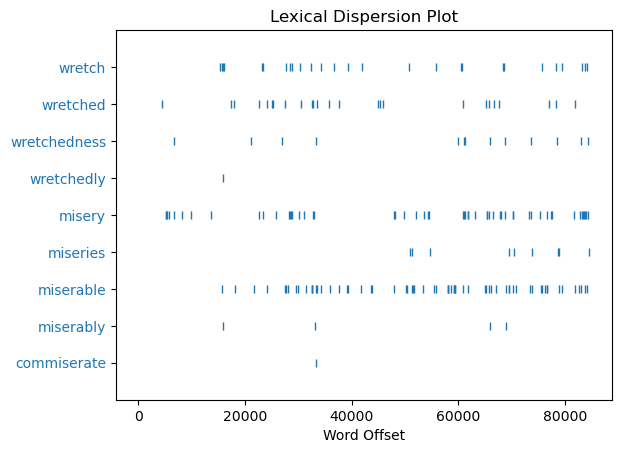

In [9]:
dalet = ['wretch', 'wretched', 'wretchedness', 'wretchedly', 'misery', 'miseries', 'miserable', 'miserably', 'commiserate']
text_frank.dispersion_plot(dalet)

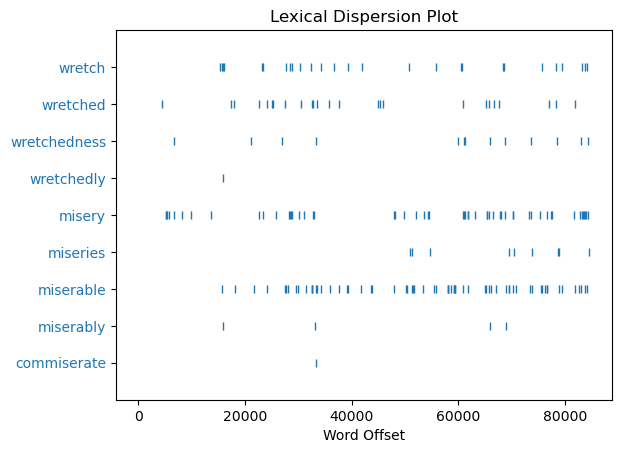

In [10]:
# Save plot as file
from nltk.draw.util import CanvasFrame
import matplotlib.pyplot as plt

disp = nltk.draw.dispersion_plot(text_frank, dalet)

plt.savefig("./images/unstemmed_disp.png", format="png", bbox_inches='tight')

It would be nice if we could just group those words together. Let's try using a stemmer to reduce the words to stems.

### Using a Stemmer

First up, let's try using LancasterStemmer on our list of tokens

In [11]:
from nltk.stem.lancaster import LancasterStemmer

stemmer = LancasterStemmer()
[(tok, stemmer.stem(tok)) for tok in dalet]

[('wretch', 'wretch'),
 ('wretched', 'wretch'),
 ('wretchedness', 'wretch'),
 ('wretchedly', 'wretch'),
 ('misery', 'misery'),
 ('miseries', 'misery'),
 ('miserable', 'mis'),
 ('miserably', 'mis'),
 ('commiserate', 'com')]

This stemmer has reduced all of the *wretched* words into the `wretch` stem, but the *miserable* words are spread across `misery`, `mis`, and `com`. 

We have to weigh whether or not we want to use this stemmer now. It's really unfortunate that *miserable* got reduced into `mis`, and *commiserate* into `com`. Your mileage may vary with stemming, so let's give this one a try on our whole book and see how that affects things.

In [12]:
lanc_stemmed_tokens = [stemmer.stem(tok) for tok in tokens]
lanc_stemmed_tokens[15250:15278]

['how',
 'can',
 'i',
 'describ',
 'my',
 'emot',
 'at',
 'thi',
 'catastroph',
 ',',
 'or',
 'how',
 'delin',
 'the',
 'wretch',
 'whom',
 'with',
 'such',
 'infinit',
 'pain',
 'and',
 'car',
 'i',
 'had',
 'endeavo',
 'to',
 'form',
 '?']

This doesn't look too bad! Let's generate a distribution plot for the stems we produced.

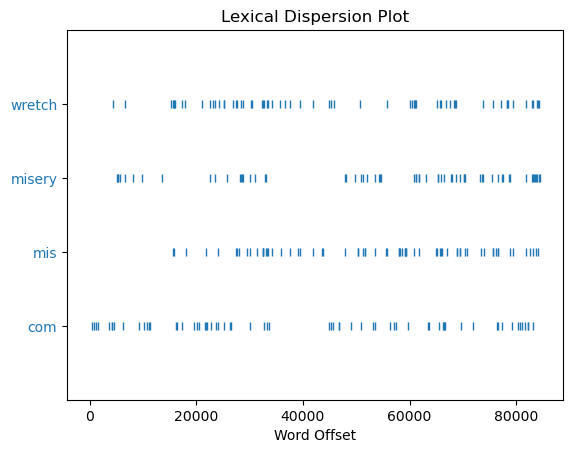

In [13]:
lanc_stemmed_text_frank = nltk.Text(lanc_stemmed_tokens)
lanc_stemmed_text_frank.dispersion_plot(['wretch', 'misery', 'mis', 'com'])

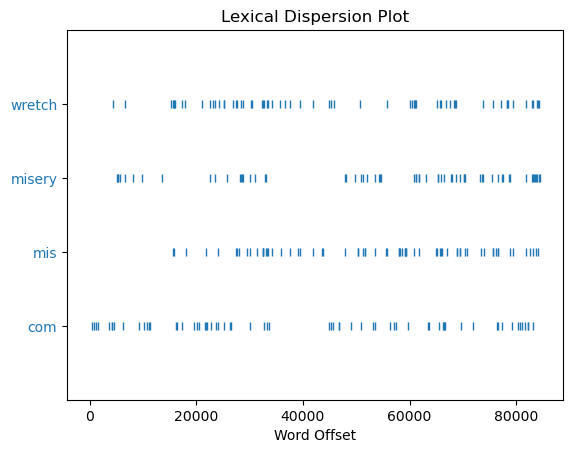

In [14]:
disp = nltk.draw.dispersion_plot(lanc_stemmed_text_frank, ['wretch', 'misery', 'mis', 'com'])

plt.savefig("./images/lancstemmed_disp.png", format="png", bbox_inches='tight')

In [15]:
len(lanc_stemmed_text_frank.vocab()), len(text_frank.vocab())

(4000, 6826)

At a glance, we can see that the stem `wretch` does a great job at uniting its related words. `misery` seems good enough as well. Overall, `mis` seems fine, though we'd better be careful because it might have too much since it's so heavily reduced.

But `com` is clearly grabbing far more words than just *commiserate*... This stemmer does a great job at reducing the vocabulary of our book (it decreased the book's number of unique tokens from 6826 to 4000), but it overdid it in my opinion. Less zealous stemmers exist, and they're handy for keeping relevant words tied to the same stem, but stemming doesn't take the semantic meanings of words into account.

For a more careful approach to tackling this problem, we should look at Lemmatization.

## What is Lemmatization?
Let's look at that dictionary entry again.

*Muscle* is a verb, but it's also a noun; and *muscled* can be a verb or an adjective. We can also use the noun form of muscle as an adjective, like when we differentiate a *<ins>muscle</ins> shirt* from a regular old *shirt*.

Should we consider the words *muscle* (noun), *muscle* (verb), and *muscle* (adj) to be only one word?

In truth, dictionaries do not contain stems. The group of words that a dictionary entry unites is called a **lexeme**, and the word chosen for that entry is called the **lemma**. In the above dictionary entry, *muscle* (verb) is the lemma for the lexeme which includes the verb forms of muscles, muscled, and muscling. But there are also entries for the noun and adjectival forms.

Lemmatization takes the part of speech into account.

We'll need our tokens, and to have the part of speech for each token, which we can get with `nltk.pos_tag(tokens)`:

In [16]:
tagged_tokens = nltk.pos_tag(tokens)
tagged_tokens[:3]

[('frankenstein', 'NN'), (';', ':'), ('or', 'CC')]

`pos_tag` isn't perfect, but there really isn't a way to perfectly compute parts of speech yet.

We want to use WordNetLemmatizer, but it requires that the parts of speech be either `'n'` for noun, `'v'` for verbs, `'a'` for adjectives, and `'r'` for adverbs. So let's also create a function to convert our tags to fit these standards.

In [17]:
def pos_format(tag : str):
    if tag.startswith('NN'):
        return 'n'
    if tag.startswith('V'):
        return 'v'
    if tag.startswith('JJ'):
        return 'a'
    if tag.startswith('RB'):
        return 'r'
    return 'n'


Now we can try lemmatizing our tokens

In [18]:
from nltk.stem.wordnet import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()
lemmed_tokens = [lemmatizer.lemmatize(tok, pos_format(pos)) 
                 for tok, pos in tagged_tokens]

lemmed_tokens[15250:15278]

['how',
 'can',
 'i',
 'describe',
 'my',
 'emotion',
 'at',
 'this',
 'catastrophe',
 ',',
 'or',
 'how',
 'delineate',
 'the',
 'wretch',
 'whom',
 'with',
 'such',
 'infinite',
 'pain',
 'and',
 'care',
 'i',
 'have',
 'endeavour',
 'to',
 'form',
 '?']


This looks very similar to the unlemmatized and unstemmed passage, so let me highlight the changes
> how can i describe my emotion~~s~~ at this catastrophe, or how delineate the
wretch whom with such infinite pain~~s~~ and care i ha~~d~~**ve** endeavour~~ed~~ to form?

*emotions* and *pain* were made singular, and *had* and *endeavoured* were made present tense.

Here's what lemmatizing a larger passage looks like:
#### Unlemmatized:

In [19]:
' '.join(tokens[15713:15824])

'his jaws opened , and he muttered some inarticulate sounds , while a grin wrinkled his cheeks . he might have spoken , but i did not hear ; one hand was stretched out , seemingly to detain me , but i escaped , and rushed down stairs . i took refuge in the court-yard belonging to the house which i inhabited ; where i remained during the rest of the night , walking up and down in the greatest agitation , listening attentively , catching and fearing each sound as if it were to announce the approach of the demoniacal corpse to which i had so miserably given life .'

#### Lemmatized:

In [20]:
' '.join(lemmed_tokens[15713:15824])

'his jaw open , and he mutter some inarticulate sound , while a grin wrinkle his cheek . he might have speak , but i do not hear ; one hand be stretch out , seemingly to detain me , but i escape , and rush down stairs . i take refuge in the court-yard belonging to the house which i inhabit ; where i remain during the rest of the night , walk up and down in the great agitation , listen attentively , catch and fear each sound a if it be to announce the approach of the demoniacal corpse to which i have so miserably give life .'

Overall, this was able to reduce the tokens to lemmas far more fitting than the Lancaster stemmer could with stems. 

I want to highlight a success and a failure. 

**Success:** The function I wrote to convert parts of speech and the lemmatizer were able to recognize *down stairs* as two parts of a noun instead of thinking *stairs* was the plural of *stair*.

**Failure**: My part of speech function defaulted to tagging tokens that weren't nouns, adjectives, verbs, or adverbs as if they were nouns. That caused the lemmatizer to convert `'as'` into `'a'`.

## Conclusion
I hope this walkthrough and explainer was helpful in covering why and how natural language text is preprocessed. Along with this article, I have provided a Jupyter Notebook with the code shown here. If you'd like to play with this more, I would highly recommend you download it and take a look.

Take care everyone.